# Filip: používanie AI a riešenie digitálnych problémov

**Otázka:** Ako súvisí frekvencia používania AI pri učení s úspešnosťou pri riešení
digitálnych problémov u českých a slovenských žiakov?

Pracujeme so spoločným výberom Česka a Slovenska. Najprv ukážeme všetky skupiny,
potom pomocou **4ft-Mineru** vyhľadáme pravidlá. Doplnkovým kontextom je čas používania
digitálnych nástrojov na učenie pred vyučovaním a po ňom.

**Čo meria výsledok:** celkové skóre *Computational Problem Solving* z oblasti
*Learning in the Digital World* (LDW). Žiaci riešia úlohy pomocou programovania
a počítačových modelov. Napríklad v úlohe **Recycling Claw** zostavujú z blokov
program pre robotické rameno, ktoré triedi predmety, a riešenie skúšajú a opravujú.
Použijeme hotové skóre testu, nie vlastné hodnotenie jednotlivých programov.

Používanie AI zisťuje samostatná dotazníková otázka o chatbotových nástrojoch na
učenie všeobecne. Test LDW meria riešenie digitálnych úloh; skóre nevyjadruje
schopnosť používať AI. Hľadáme **súvislosť, nie príčinný účinok AI**.

Zdroje: [OECD – vysvetlenie LDW](https://www.oecd.org/en/topics/sub-issues/learning-in-the-digital-world/pisa-2025-learning-in-the-digital-world.html),
[OECD – ukážka Recycling Claw](https://www.oecd.org/en/publications/pisa-2025-results-volume-i_73451bc5-en/full-report/released-items-from-the-pisa-2025-science-and-learning-in-the-digital-world-ldw-assessments_b90631fa.html),
[CleverMiner](https://www.cleverminer.org/doc/index.html).

**Spustenie:** podľa README nainštaluj závislosti a priprav Parquet spolu s JSON
metadátami. Zvoľ projektové jadro Python a spusti všetky bunky zhora nadol.
Notebook funguje z koreňa projektu aj z priečinka `notebooks/`.
Výstupy vzniknú v `outputs/filip/`; opakované spustenie ich obnoví.

## 1. Načítanie dát a nastavenia dohodnuté pred hľadaním pravidiel

Parquet nemeníme ani znova nevytvárame. Čítame iba potrebné stĺpce a obe krajiny.
Prah **Base ≥ 100** znamená aspoň 100 žiakov spĺňajúcich podmienku aj vyšší výsledok.
**Confidence ≥ 30 %** znamená, že vyšší výsledok má aspoň 30 % žiakov danej skupiny.
Prahy po zobrazení výsledkov neupravujeme.

In [1]:
from pathlib import Path
from importlib.metadata import version
import contextlib
import io
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display
from cleverminer import cleverminer

PROJECT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/processed/student_full.parquet").is_file()),
    None,
)
if PROJECT is None:
    raise FileNotFoundError("Otvor projekt alebo notebooks/ a priprav plný Parquet podľa README.")

DATA = PROJECT / "data/processed/student_full.parquet"
METADATA = PROJECT / "data/processed/student_full_metadata.json"
# Voliteľná cesta umožňuje overiť notebook bez prepisovania bežných výstupov.
OUTPUT = Path(os.environ.get("PISA_FILIP_OUTPUT_DIR", str(PROJECT / "outputs/filip")))
OUTPUT.mkdir(parents=True, exist_ok=True)

COUNTRIES = ["CZE", "SVK"]
COUNTRY_NAMES = {"CZE": "Česko", "SVK": "Slovensko"}
AI_SOURCE = "ST438Q04DA"
TIME_SOURCE = "ST326Q02JA"
PVS = [f"PV{i}CMPS" for i in range(1, 11)]
MIN_BASE, MIN_CONF = 100, 0.30
COLUMNS = ["CNT", "CNTSTUID", AI_SOURCE, TIME_SOURCE, "W_FSTUWT", *PVS]

if not METADATA.is_file():
    raise FileNotFoundError("Doplň aj student_full_metadata.json z rovnakého prevodu ako Parquet.")
metadata = json.loads(METADATA.read_text(encoding="utf-8"))
embedded = pq.read_schema(DATA).metadata or {}
if b"pisa_metadata" not in embedded or json.loads(embedded[b"pisa_metadata"]) != metadata:
    raise ValueError("Parquet a JSON metadáta nepatria k sebe. Použi dvojicu z rovnakého prevodu.")
by_name = {item["name"]: item for item in metadata["columns"]}
if missing := set(COLUMNS) - set(by_name):
    raise ValueError(f"V dátach chýbajú potrebné premenné: {sorted(missing)}")

raw = pq.read_table(DATA, columns=COLUMNS, filters=[("CNT", "in", COUNTRIES)]).to_pandas()
if raw.empty or set(raw["CNT"]) != set(COUNTRIES):
    raise ValueError("Výber musí obsahovať žiakov z oboch krajín.")
if raw[["CNT", "CNTSTUID"]].isna().any().any() or raw.duplicated(["CNT", "CNTSTUID"]).any():
    raise ValueError("Skontroluj chýbajúce alebo duplicitné identifikátory žiakov.")

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13})
pd.set_option("display.max_columns", 20)
print(f"Načítaných žiakov: {len(raw):,}; krajiny: {', '.join(COUNTRIES)}")
print("Verzia zdroja:", metadata["build_id"])

Cleverminer version  1.2.8
Načítaných žiakov: 15,144; krajiny: CZE, SVK
Verzia zdroja: 5606abe2b67a44599d050d7ca5e5cb41


In [2]:
variables = pd.DataFrame([
    {"premenna": name, "vyznam": by_name[name]["label"],
     "chybajuce_kody": str(by_name[name].get("missing_ranges", []))}
    for name in [AI_SOURCE, TIME_SOURCE, "PV1CMPS", "W_FSTUWT"]
])
variables.to_csv(OUTPUT / "premenne.csv", index=False, encoding="utf-8-sig")
display(variables)
for name in [AI_SOURCE, TIME_SOURCE]:
    print(name, by_name[name]["label"])
    display(pd.DataFrame(by_name[name]["value_labels"]))

,premenna,vyznam,chybajuce_kody
0,ST438Q04DA,How often do you use Artificial Intelligence c...,"[{'lo': 95.0, 'hi': 99.0}]"
1,ST326Q02JA,"This school year, about how many hours a day d...","[{'lo': 95.0, 'hi': 99.0}]"
2,PV1CMPS,Plausible Value 1 in LDW Computational Problem...,"[{'lo': 9997.0, 'hi': 9997.0}]"
3,W_FSTUWT,FINAL TRIMMED NONRESPONSE ADJUSTED STUDENT WEIGHT,[]


ST438Q04DA How often do you use Artificial Intelligence chatbots (e.g. <ChatGPT>) for your school work to do the following activities? - To help me learn


,value,label
0,1.0,Never or almost never
1,2.0,About once or twice a year
2,3.0,About once or twice a month
3,4.0,About once or twice a week
4,5.0,Every day or almost every day
5,95.0,valid skip (filter rule)
6,96.0,system missing
7,97.0,not administered/not applicable
8,98.0,invalid
9,99.0,no response


ST326Q02JA This school year, about how many hours a day do you usually use <digital resources> in the following situations? - For learning activities before and after school


,value,label
0,1.0,None
1,2.0,Up to 1 hour
2,3.0,More than 1 hour and up to 2 hours
3,4.0,More than 2 hour and up to 3 hours
4,5.0,More than 3 hour and up to 4 hours
5,6.0,More than 4 hour and up to 5 hours
6,7.0,More than 5 hour and up to 6 hours
7,8.0,More than 6 hour and up to 7 hours
8,9.0,More than 7 hours
9,95.0,valid skip (filter rule)


## 2. Chýbajúce odpovede a jeden spoločný analytický výber

Kódy ako 95–99 alebo 9997 sa líšia podľa premennej. Preto ich odstraňujeme podľa
`missing_ranges` konkrétneho stĺpca, nie jedným globálnym pravidlom.
Použijeme žiakov s platnou odpoveďou o AI, čase učenia, všetkými 10 hodnotami CMPS
a kladnou konečnou žiackou váhou. Údaje nedopĺňame odhadom.

Hlavná tabuľka aj obe úlohy 4ft-Mineru používajú **ten istý výber**.
Váhy potrebujeme na neskoršiu kontrolu; samotné hľadanie pravidiel je nevážené.

In [3]:
clean = raw.copy()
for name in [AI_SOURCE, TIME_SOURCE, "W_FSTUWT", *PVS]:
    clean[name] = pd.to_numeric(clean[name], errors="raise")
    for interval in by_name[name].get("missing_ranges", []):
        clean.loc[clean[name].between(interval["lo"], interval["hi"]), name] = np.nan
    clean[name] = clean[name].where(np.isfinite(clean[name]))

ai_ok = clean[AI_SOURCE].notna()
pv_ok = clean[PVS].notna().all(axis=1)
time_ok = clean[TIME_SOURCE].notna()
weight_ok = clean["W_FSTUWT"].notna() & clean["W_FSTUWT"].gt(0)
stages = [
    ("Pôvodný výber", pd.Series(True, index=clean.index)),
    ("Platná odpoveď o AI", ai_ok),
    ("Aj všetkých 10 výsledkov CMPS", ai_ok & pv_ok),
    ("Aj čas digitálneho učenia", ai_ok & pv_ok & time_ok),
    ("Aj platná kladná váha — analytický výber", ai_ok & pv_ok & time_ok & weight_ok),
]
flow = pd.DataFrame([
    {"krok": label, "spolu": int(mask.sum()),
     **{country: int((mask & clean["CNT"].eq(country)).sum()) for country in COUNTRIES}}
    for label, mask in stages
])
flow["vyradenych_v_kroku"] = flow["spolu"].shift(fill_value=len(clean)) - flow["spolu"]
flow["zachovane_pct"] = 100 * flow["spolu"] / len(clean)
flow.to_csv(OUTPUT / "vyber_a_vyradenie.csv", index=False, encoding="utf-8-sig")
display(flow.round(2))

missingness = pd.DataFrame([
    {"krajina": country, "premenna": name, "chyba": int(group[name].isna().sum()),
     "chyba_pct": 100 * group[name].isna().mean()}
    for country, group in clean.groupby("CNT")
    for name in [AI_SOURCE, TIME_SOURCE, *PVS]
])
missingness.to_csv(OUTPUT / "chybajuce_odpovede.csv", index=False, encoding="utf-8-sig")
analysis = clean.loc[stages[-1][1]].reset_index(drop=True).copy()
if analysis.empty or set(analysis["CNT"]) != set(COUNTRIES):
    raise ValueError("Po čistení nezostali použiteľné údaje z oboch krajín.")
print(f"Analytický výber: {len(analysis):,} žiakov ({100 * len(analysis) / len(raw):.1f} %).")

,krok,spolu,CZE,SVK,vyradenych_v_kroku,zachovane_pct
0,Pôvodný výber,15144,8462,6682,0,100.00
1,Platná odpoveď o AI,13703,7605,6098,1441,90.48
2,Aj všetkých 10 výsledkov CMPS,13703,7605,6098,0,90.48
3,Aj čas digitálneho učenia,13359,7397,5962,344,88.21
4,Aj platná kladná váha — analytický výber,13359,7397,5962,0,88.21


Analytický výber: 13,359 žiakov (88.2 %).


## 3. Kategórie a definícia vyššieho výsledku

| Premenná | Pôvodné kódy | Naše kategórie |
|---|---|---|
| AI pri učení | 1; 2–3; 4–5 | Nikdy/takmer nikdy; občas (ročne/mesačne); pravidelne (týždenne/denne) |
| Čas digitálneho učenia pred/po vyučovaní | 1–2; 3; 4–9 | 0–1 h; viac ako 1 až 2 h; viac ako 2 h denne |

Plausibilné hodnoty (PV) sú alternatívne hodnoty z modelu schopností, nie desať
samostatných testov ani presné individuálne známky. Pre základnú prieskumnú analýzu
použijeme `PV1CMPS`. **Vyšší výsledok = skóre nad 75. percentilom spoločného výberu.**
Hranicu vypočítame raz a zachováme ju pre obe krajiny aj všetkých 10 PV.
Je to analytické rozdelenie na hornú štvrtinu a ostatných, nie oficiálna úroveň PISA.

In [4]:
AI_LABELS = {"1_nikdy": "Nikdy/takmer nikdy", "2_obcas": "Občas", "3_pravidelne": "Pravidelne"}
TIME_LABELS = {"1_0_1h": "0–1 h denne", "2_1_2h": ">1–2 h denne", "3_nad_2h": ">2 h denne"}
AI_MAP = {1: "1_nikdy", 2: "2_obcas", 3: "2_obcas", 4: "3_pravidelne", 5: "3_pravidelne"}
TIME_MAP = {1: "1_0_1h", 2: "1_0_1h", 3: "2_1_2h", **{i: "3_nad_2h" for i in range(4, 10)}}
categories = pd.DataFrame({
    "ai": analysis[AI_SOURCE].map(AI_MAP),
    "cas": analysis[TIME_SOURCE].map(TIME_MAP),
})
if categories.isna().any().any():
    raise ValueError("Neznámy platný kód odpovede. Najprv skontroluj codebook a kategórie.")
THRESHOLD = float(analysis["PV1CMPS"].quantile(0.75))
target = analysis["PV1CMPS"].gt(THRESHOLD)
if not 0 < target.mean() < 1:
    raise ValueError("Výsledok sa nedá rozdeliť na vyšší a ostatný.")
BASELINE = float(target.mean())
rules_data = categories.assign(vysledok=np.where(target, "1_vyssi", "2_ostatny"))

category_counts = pd.DataFrame([
    {"premenna": name, "kod": key, "kategoria": label,
     "n": int(categories[name].eq(key).sum()), "podiel_pct": 100 * categories[name].eq(key).mean()}
    for name, labels in [("ai", AI_LABELS), ("cas", TIME_LABELS)]
    for key, label in labels.items()
])
category_counts.to_csv(OUTPUT / "kategorie.csv", index=False, encoding="utf-8-sig")
display(category_counts.round(2))
print(f"Spoločná hranica PV1CMPS: > {THRESHOLD:.8f} bodu.")
print(f"Vyšší výsledok: {int(target.sum()):,} z {len(analysis):,} žiakov ({100 * BASELINE:.2f} %).")

,premenna,kod,kategoria,n,podiel_pct
0,ai,1_nikdy,Nikdy/takmer nikdy,2588,19.37
1,ai,2_obcas,Občas,4398,32.92
2,ai,3_pravidelne,Pravidelne,6373,47.71
3,cas,1_0_1h,0–1 h denne,7330,54.87
4,cas,2_1_2h,>1–2 h denne,3048,22.82
5,cas,3_nad_2h,>2 h denne,2981,22.31


Spoločná hranica PV1CMPS: > 584.27639105 bodu.
Vyšší výsledok: 3,340 z 13,359 žiakov (25.00 %).


## 4. Všetky skupiny: tabuľka a hlavný graf

**Confidence** je podiel vyšších výsledkov v skupine. **Lift** tento podiel delí
podielom v celom analytickom výbere: napríklad lift 1,2 znamená 1,2-násobný podiel,
nie zvýšenie o 20 percentuálnych bodov ani účinok používania AI.
V tabuľkách je `base` počet žiakov s vyšším výsledkom v skupine; `n` je veľkosť skupiny.

,podmienka,n,base,podiel_vyssi_pct,lift
0,Nikdy/takmer nikdy,2588,671,25.927,1.037
1,Občas,4398,1013,23.033,0.921
2,Pravidelne,6373,1656,25.985,1.039


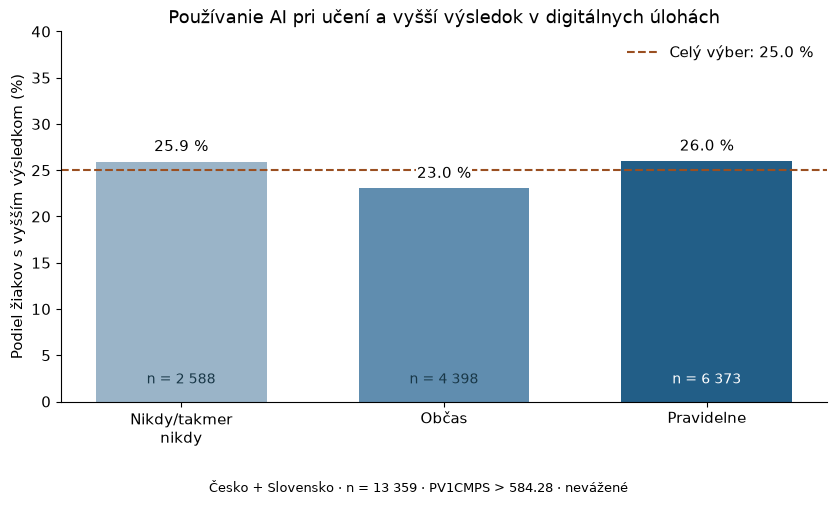

In [5]:
def mask_for(conditions):
    mask = pd.Series(True, index=analysis.index)
    for name, value in conditions.items():
        mask &= categories[name].eq(value)
    return mask


def describe_conditions(conditions):
    text = AI_LABELS[conditions["ai"]]
    if "cas" in conditions:
        text += " + digitálne učenie " + TIME_LABELS[conditions["cas"]]
    return text


def metrics(mask, outcome, universe=None):
    if universe is None:
        universe = pd.Series(True, index=analysis.index)
    mask = mask & universe
    a = int((mask & outcome).sum())
    b = int((mask & ~outcome).sum())
    c = int((~mask & universe & outcome).sum())
    d = int((~mask & universe & ~outcome).sum())
    weights = analysis["W_FSTUWT"]
    baseline = float(outcome[universe].mean())
    weighted_baseline = float(weights[universe & outcome].sum() / weights[universe].sum())
    confidence = a / (a + b) if a + b else np.nan
    denominator = weights[mask].sum()
    weighted = float(weights[mask & outcome].sum() / denominator) if denominator > 0 else np.nan
    return {
        "n": a + b, "base": a, "a": a, "b": b, "c": c, "d": d,
        "confidence": confidence, "podiel_vyssi_pct": 100 * confidence,
        "baseline": baseline, "lift": confidence / baseline if baseline > 0 else np.nan,
        "confidence_vazena": weighted, "podiel_vyssi_vazeny_pct": 100 * weighted,
        "baseline_vazena": weighted_baseline,
        "lift_vazeny": weighted / weighted_baseline if weighted_baseline > 0 else np.nan,
        "splna_prahy": bool(a >= MIN_BASE and confidence >= MIN_CONF),
    }


CONDITIONS = {f"AI_{i}": {"ai": ai} for i, ai in enumerate(AI_LABELS, 1)}
CONDITIONS.update({
    f"AI_CAS_{i}_{j}": {"ai": ai, "cas": time}
    for i, ai in enumerate(AI_LABELS, 1) for j, time in enumerate(TIME_LABELS, 1)
})
candidates = pd.DataFrame([
    {"id": key, "typ": "AI" if len(conditions) == 1 else "AI + čas",
     "ai": conditions["ai"], "cas": conditions.get("cas", ""),
     "podmienka": describe_conditions(conditions), **metrics(mask_for(conditions), target)}
    for key, conditions in CONDITIONS.items()
])
ai_table = candidates.loc[candidates["typ"].eq("AI")].copy()
combinations = candidates.loc[candidates["typ"].eq("AI + čas")].copy()
ai_table.to_csv(OUTPUT / "ai_skupiny.csv", index=False, encoding="utf-8-sig")
combinations.to_csv(OUTPUT / "ai_a_cas.csv", index=False, encoding="utf-8-sig")
candidates.to_csv(OUTPUT / "vsetky_kandidatske_pravidla.csv", index=False, encoding="utf-8-sig")
display(ai_table[["podmienka", "n", "base", "podiel_vyssi_pct", "lift"]].round(3))


def finish_figure(fig, name, note):
    fig.text(0.5, 0.015, note, ha="center", va="bottom", fontsize=9)
    fig.tight_layout(rect=[0, 0.075, 1, 1])
    fig.savefig(OUTPUT / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


AI_TICKS = ["Nikdy/takmer\nnikdy", "Občas", "Pravidelne"]
NOTE = f"Česko + Slovensko · n = {len(analysis):,} · PV1CMPS > {THRESHOLD:.2f}".replace(",", " ")
fig, ax = plt.subplots(figsize=(8.5, 5.1))
bars = ax.bar(AI_TICKS, ai_table["podiel_vyssi_pct"], color=["#9AB4C8", "#608DAF", "#225E87"], width=0.65)
ax.bar_label(bars, labels=[f"{value:.1f} %" for value in ai_table["podiel_vyssi_pct"]], padding=5,
             fontsize=11, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
for position, row in enumerate(ai_table.itertuples()):
    ax.text(position, 1.6, f"n = {row.n:,}".replace(",", " "), ha="center", va="bottom",
            fontsize=10, color="white" if position == 2 else "#183747")
ax.axhline(100 * BASELINE, color="#9A4F21", linestyle="--", label=f"Celý výber: {100 * BASELINE:.1f} %")
ax.set(title="Používanie AI pri učení a vyšší výsledok v digitálnych úlohách", ylabel="Podiel žiakov s vyšším výsledkom (%)", ylim=(0, max(40, ai_table["podiel_vyssi_pct"].max() + 10)))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
finish_figure(fig, "01_ai_a_vysledok", NOTE + " · nevážené")

## 5. Doplnkový kontext: čas digitálneho učenia

Zobrazíme všetkých deväť kombinácií, vrátane tých s nižším podielom vyšších výsledkov.
Čas zahŕňa učenie pomocou digitálnych nástrojov všeobecne, nielen AI.
Z rozdielov nemôžeme určiť, koľko času by sa mal žiak učiť alebo či konkrétny čas
zlepšuje výkon.

,podmienka,n,base,podiel_vyssi_pct,lift,splna_prahy
3,Nikdy/takmer nikdy + digitálne učenie 0–1 h denne,1676,436,26.014,1.040,False
4,Nikdy/takmer nikdy + digitálne učenie >1–2 h d...,474,144,30.380,1.215,True
5,Nikdy/takmer nikdy + digitálne učenie >2 h denne,438,91,20.776,0.831,False
6,Občas + digitálne učenie 0–1 h denne,2451,583,23.786,0.951,False
7,Občas + digitálne učenie >1–2 h denne,1010,263,26.040,1.042,False
8,Občas + digitálne učenie >2 h denne,937,167,17.823,0.713,False
9,Pravidelne + digitálne učenie 0–1 h denne,3203,795,24.820,0.993,False
10,Pravidelne + digitálne učenie >1–2 h denne,1564,479,30.627,1.225,True
11,Pravidelne + digitálne učenie >2 h denne,1606,382,23.786,0.951,False


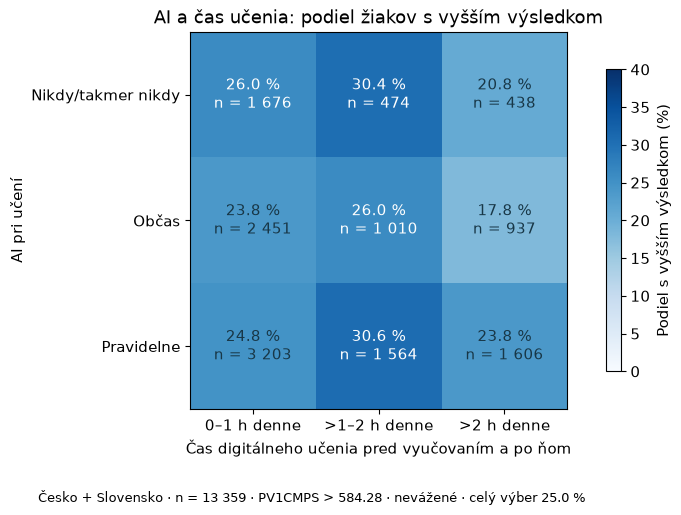

In [6]:
display(combinations[["podmienka", "n", "base", "podiel_vyssi_pct", "lift", "splna_prahy"]].round(3))
heat = combinations.pivot(index="ai", columns="cas", values="podiel_vyssi_pct").reindex(index=AI_LABELS, columns=TIME_LABELS)
sizes = combinations.pivot(index="ai", columns="cas", values="n").reindex(index=AI_LABELS, columns=TIME_LABELS)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
image = ax.imshow(heat.to_numpy(), cmap="Blues", vmin=0, vmax=max(40, float(heat.max().max())))
for row in range(3):
    for col in range(3):
        value = heat.iloc[row, col]
        ax.text(col, row, f"{value:.1f} %\nn = {int(sizes.iloc[row, col]):,}".replace(",", " "),
                ha="center", va="center", fontsize=11, color="white" if value >= 25 else "#183747")
ax.set_xticks(range(3), list(TIME_LABELS.values()))
ax.set_yticks(range(3), list(AI_LABELS.values()))
ax.set(xlabel="Čas digitálneho učenia pred vyučovaním a po ňom", ylabel="AI pri učení", title="AI a čas učenia: podiel žiakov s vyšším výsledkom")
fig.colorbar(image, ax=ax, label="Podiel s vyšším výsledkom (%)", shrink=0.8)
finish_figure(fig, "02_ai_a_cas", NOTE + f" · nevážené · celý výber {100 * BASELINE:.1f} %")

## 6. Hľadanie pravidiel 4ft-Minerom

**Beh A:** jedna kategória AI ⇒ vyšší výsledok (3 možné podmienky).
**Beh B:** jedna kategória AI **a** jedna kategória času ⇒ vyšší výsledok (9 kombinácií).
Nezlučujeme kategórie a nevytvárame pravidlá iba o čase. Krajina nie je atribútom
na hľadanie pravidiel; zostáva kontrolou spoločného výberu.

Vopred určené prahy sú Base ≥ 100 a confidence ≥ 30 %. Všetky nájdené pravidlá
ponecháme v exporte. Prázdny zoznam je platný výsledok.

In [7]:
def run_miner(attributes):
    stream = io.StringIO()
    with contextlib.redirect_stdout(stream):
        miner = cleverminer(
            df=rules_data[[*attributes, "vysledok"]].copy(), proc="4ftMiner",
            quantifiers={"Base": MIN_BASE, "conf": MIN_CONF},
            ante={"attributes": [{"name": name, "type": "subset", "minlen": 1, "maxlen": 1} for name in attributes],
                  "minlen": len(attributes), "maxlen": len(attributes), "type": "con"},
            succ={"attributes": [{"name": "vysledok", "type": "lcut", "minlen": 1, "maxlen": 1}],
                  "minlen": 1, "maxlen": 1, "type": "con"},
        )
        miner.print_summary()
        miner.print_rulelist()
    return miner, stream.getvalue()


miners = {}
found_rows = []
for run, attrs in [("A_AI", ["ai"]), ("B_AI_CAS", ["ai", "cas"])]:
    miner, log = run_miner(attrs)
    miners[run] = miner
    (OUTPUT / f"4ft_{run}.txt").write_text(log, encoding="utf-8")
    actual_keys = set()
    for rule in miner.result["rules"]:
        struct = rule["cedents_struct"]
        assert struct["succ"] == {"vysledok": ["1_vyssi"]}, "Nesprávny cieľ pravidla."
        conditions = {name: values[0] for name, values in struct["ante"].items()}
        assert set(conditions) == set(attrs) and all(len(v) == 1 for v in struct["ante"].values())
        key = next(key for key, candidate in CONDITIONS.items() if candidate == conditions)
        assert key not in actual_keys, "Duplicitné pravidlo."
        actual_keys.add(key)
        manual = metrics(mask_for(conditions), target)
        # Nezávislé overenie presných počtov, nie iba porovnanie zaokrúhlených percent.
        assert list(miner.get_fourfold(rule["rule_id"])) == [manual[c] for c in ["a", "b", "c", "d"]]
        assert np.isclose(rule["params"]["conf"], manual["confidence"])
        assert int(rule["params"]["base"]) == manual["base"]
        found_rows.append({"id": key, "beh": run, "miner_id": rule["rule_id"]})
    expected = {
        row.id for row in candidates.itertuples()
        if len(CONDITIONS[row.id]) == len(attrs) and row.splna_prahy
    }
    assert actual_keys == expected, f"Miner a úplný ručný prepočet sa líšia: {run}."
    # Miner môže vetvu vylúčiť podľa Base skôr; úplnosť overuje porovnanie všetkých kandidátov vyššie.
    print(f"{run}: {len(actual_keys)} pravidiel; úplnosť a štvorpoľné tabuľky overené.")

found_ids = pd.DataFrame(found_rows, columns=["id", "beh", "miner_id"])
found = found_ids.merge(candidates, on="id", how="left", validate="one_to_one")
found.to_csv(OUTPUT / "najdene_pravidla.csv", index=False, encoding="utf-8-sig")
display(found[["id", "podmienka", "n", "base", "podiel_vyssi_pct", "lift"]].round(3))

selected_ids = []
for kind in ["AI", "AI + čas"]:
    available = found.loc[found["typ"].eq(kind)].sort_values(
        ["confidence", "base", "id"], ascending=[False, False, True], kind="stable")
    if not available.empty:
        selected_ids.append(available.iloc[0]["id"])
selected = candidates.loc[candidates["id"].isin(selected_ids)].copy()
selected.to_csv(OUTPUT / "vybrane_pravidla.csv", index=False, encoding="utf-8-sig")
print("Výber do prezentácie:", selected_ids or "žiadne pravidlo nesplnilo prahy")

A_AI: 0 pravidiel; úplnosť a štvorpoľné tabuľky overené.
B_AI_CAS: 2 pravidiel; úplnosť a štvorpoľné tabuľky overené.


,id,podmienka,n,base,podiel_vyssi_pct,lift
0,AI_CAS_1_2,Nikdy/takmer nikdy + digitálne učenie >1–2 h d...,474,144,30.380,1.215
1,AI_CAS_3_2,Pravidelne + digitálne učenie >1–2 h denne,1564,479,30.627,1.225


Výber do prezentácie: ['AI_CAS_3_2']


## 7. Citlivosť na plausibilné hodnoty a žiacke váhy

Pre všetkých 12 podmienok zopakujeme výpočty na `PV1CMPS` až `PV10CMPS`.
Výber žiakov, kategórie aj bodová hranica zostávajú rovnaké. Zhrnieme priemer
a rozsah confidence a počet PV, v ktorých podmienka spĺňa pôvodné prahy.

Kontrola váh používa `W_FSTUWT` pre spoločnú populáciu žiakov oboch krajín.
Krajiny preto nemajú automaticky rovnakú váhu. **Vážený lift delíme váženým podielom
vyšších výsledkov v celom výbere**, nie neváženými 25 %.

Rozsah medzi PV nie je interval spoľahlivosti ani nezávislé potvrdenie výsledku.
Nerátame výberovú neistotu pomocou replikačných váh, preto nevyvodzujeme štatistickú
významnosť. Váženie ani PV kontroly samy neodstránia vplyv ďalších premenných.

In [8]:
robust_detail = pd.DataFrame([
    {"id": key, "PV": pv, **metrics(mask_for(conditions), analysis[pv].gt(THRESHOLD))}
    for key, conditions in CONDITIONS.items() for pv in PVS
])
robust_summary = robust_detail.groupby("id", sort=False).agg(
    n=("n", "first"), confidence_priemer=("confidence", "mean"),
    confidence_min=("confidence", "min"), confidence_max=("confidence", "max"),
    lift_priemer=("lift", "mean"), confidence_vazena_priemer=("confidence_vazena", "mean"),
    lift_vazeny_priemer=("lift_vazeny", "mean"), PV_splnajucich_prahy=("splna_prahy", "sum"),
).reset_index()
robust_summary = robust_summary.merge(candidates[["id", "podmienka"]], on="id", validate="one_to_one")
robust_detail.to_csv(OUTPUT / "citlivost_10pv_detail.csv", index=False, encoding="utf-8-sig")
robust_summary.to_csv(OUTPUT / "citlivost_10pv_suhrn.csv", index=False, encoding="utf-8-sig")
display(robust_summary.round(4))

weights = analysis["W_FSTUWT"]
country_shares = analysis.groupby("CNT").agg(n=("CNTSTUID", "size"), suma_vah=("W_FSTUWT", "sum"))
country_shares["podiel_nevazeny_pct"] = 100 * country_shares["n"] / len(analysis)
country_shares["podiel_vazeny_pct"] = 100 * country_shares["suma_vah"] / weights.sum()
country_shares.to_csv(OUTPUT / "zastupenie_krajin.csv", encoding="utf-8-sig")
display(country_shares.round(2))

,id,n,confidence_priemer,confidence_min,confidence_max,lift_priemer,confidence_vazena_priemer,lift_vazeny_priemer,PV_splnajucich_prahy,podmienka
0,AI_1,2588,0.2582,0.2427,0.2678,1.0294,0.2468,1.0506,0,Nikdy/takmer nikdy
1,AI_2,4398,0.2327,0.2281,0.2383,0.9275,0.2181,0.9283,0,Občas
2,AI_3,6373,0.2604,0.2523,0.2655,1.0381,0.2421,1.0305,0,Pravidelne
3,AI_CAS_1_1,1676,0.2567,0.2387,0.2697,1.0232,0.2511,1.0688,0,Nikdy/takmer nikdy + digitálne učenie 0–1 h denne
4,AI_CAS_1_2,474,0.3122,0.2848,0.3249,1.2447,0.2835,1.2066,9,Nikdy/takmer nikdy + digitálne učenie >1–2 h d...
5,AI_CAS_1_3,438,0.2057,0.1849,0.2283,0.8202,0.1867,0.7952,0,Nikdy/takmer nikdy + digitálne učenie >2 h denne
6,AI_CAS_2_1,2451,0.2423,0.2366,0.2501,0.9659,0.2261,0.9625,0,Občas + digitálne učenie 0–1 h denne
7,AI_CAS_2_2,1010,0.2583,0.2376,0.2772,1.0296,0.2463,1.0484,0,Občas + digitálne učenie >1–2 h denne
8,AI_CAS_2_3,937,0.1799,0.1708,0.1900,0.7173,0.1642,0.6987,0,Občas + digitálne učenie >2 h denne
9,AI_CAS_3_1,3203,0.2516,0.2416,0.2576,1.0031,0.2322,0.9886,0,Pravidelne + digitálne učenie 0–1 h denne


,n,suma_vah,podiel_nevazeny_pct,podiel_vazeny_pct
CNT,,,,
CZE,7397,97874.92,55.37,68.83
SVK,5962,44330.00,44.63,31.17


## 8. Kontrola osobitne v Česku a na Slovensku

Hranica vyššieho výsledku zostáva spoločná. V každej krajine preto nemusí byť presne
25 % vyšších výsledkov. Krajinný lift porovnávame s vlastným referenčným podielom
danej krajiny. Táto kontrola pomáha posúdiť vplyv zloženia spoločného výberu;
nie je to samostatná porovnávacia úloha SD4ft ani úplná kontrola všetkých rušivých faktorov.

,krajina,podmienka,n,podiel_vyssi_pct,baseline,lift,podiel_vyssi_vazeny_pct,lift_vazeny
0,CZE,Nikdy/takmer nikdy,1419,29.810,0.292,1.021,26.833,1.077
10,CZE,Občas,2389,27.124,0.292,0.929,22.983,0.923
20,CZE,Pravidelne,3589,30.315,0.292,1.039,25.483,1.023
120,SVK,Nikdy/takmer nikdy,1169,21.215,0.198,1.071,20.369,1.033
130,SVK,Občas,2009,18.168,0.198,0.917,18.299,0.928
140,SVK,Pravidelne,2784,20.402,0.198,1.030,20.480,1.039


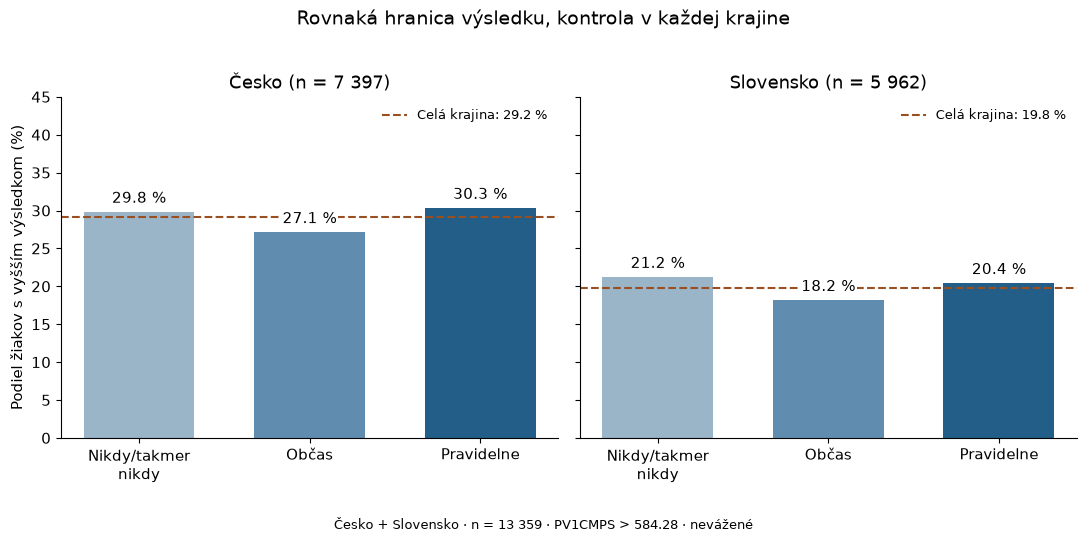

In [9]:
country_detail = pd.DataFrame([
    {"krajina": country, "id": key, "PV": pv, "podmienka": describe_conditions(conditions),
     **metrics(mask_for(conditions), analysis[pv].gt(THRESHOLD), analysis["CNT"].eq(country))}
    for country in COUNTRIES for key, conditions in CONDITIONS.items() for pv in PVS
])
country_detail.to_csv(OUTPUT / "krajiny_10pv_detail.csv", index=False, encoding="utf-8-sig")
country_pv1 = country_detail.loc[country_detail["PV"].eq("PV1CMPS")].copy()
country_pv1.to_csv(OUTPUT / "krajiny_pv1.csv", index=False, encoding="utf-8-sig")
country_ai = country_pv1.loc[country_pv1["id"].isin(ai_table["id"])].copy()
display(country_ai[["krajina", "podmienka", "n", "podiel_vyssi_pct", "baseline", "lift", "podiel_vyssi_vazeny_pct", "lift_vazeny"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
country_ylim = max(45, float(country_ai["podiel_vyssi_pct"].max()) + 10)
for ax, country in zip(axes, COUNTRIES):
    table = country_ai.loc[country_ai["krajina"].eq(country)].set_index("id").loc[ai_table["id"]]
    bars = ax.bar(AI_TICKS, table["podiel_vyssi_pct"], color=["#9AB4C8", "#608DAF", "#225E87"], width=0.65)
    ax.bar_label(bars, fmt="%.1f %%", padding=4,
                 bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
    baseline = float(table.iloc[0]["baseline"])
    ax.axhline(100 * baseline, color="#9A4F21", linestyle="--", label=f"Celá krajina: {100 * baseline:.1f} %")
    ax.set(title=f"{COUNTRY_NAMES[country]} (n = {int(table['n'].sum()):,})".replace(",", " "), ylim=(0, country_ylim))
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Podiel žiakov s vyšším výsledkom (%)")
fig.suptitle("Rovnaká hranica výsledku, kontrola v každej krajine", y=1.02, fontsize=14)
finish_figure(fig, "03_kontrola_krajin", NOTE + " · nevážené")

## 9. Vybrané pravidlá a štvorpoľné tabuľky

Do podkladov vyberáme najvyššiu confidence zo samostatnej AI a z kombinácií, ak
pravidlo splnilo prahy. Pri zhode rozhoduje Base a potom stabilné ID.
Výber vznikol na rovnakých dátach ako hodnotenie, preto ide o **prieskumné príklady**.
Ostatné kombinácie sú naďalej dostupné v úplných tabuľkách.

**Pravidelne + digitálne učenie >1–2 h denne ⇒ vyšší výsledok**

,Vyšší výsledok,Ostatný výsledok
Spĺňa podmienku,479,1085
Nespĺňa podmienku,2861,8934


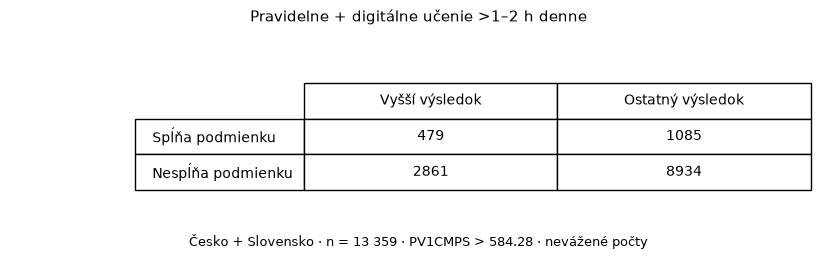

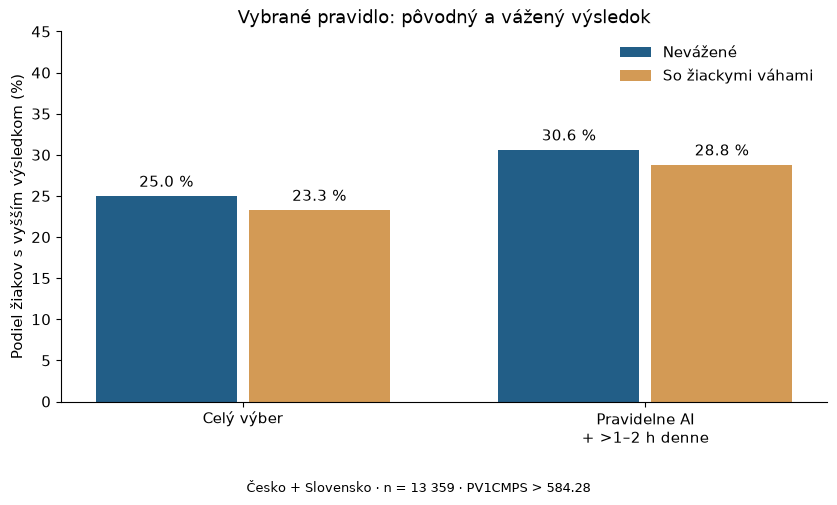

In [10]:
fourfold_rows = []
for row in selected.itertuples():
    table = pd.DataFrame(
        [[row.a, row.b], [row.c, row.d]],
        index=["Spĺňa podmienku", "Nespĺňa podmienku"],
        columns=["Vyšší výsledok", "Ostatný výsledok"],
    )
    table.to_csv(OUTPUT / f"stvorpolna_{row.id}.csv", encoding="utf-8-sig")
    display(Markdown(f"**{row.podmienka} ⇒ vyšší výsledok**"))
    display(table)
    fourfold_rows.append({"id": row.id, "a": row.a, "b": row.b, "c": row.c, "d": row.d})
    fig, ax = plt.subplots(figsize=(8.5, 2.6))
    ax.axis("off")
    picture = ax.table(cellText=table.to_numpy(), rowLabels=table.index, colLabels=table.columns,
                       cellLoc="center", loc="center", bbox=[0.36, 0.15, 0.62, 0.6])
    picture.auto_set_font_size(False)
    picture.set_fontsize(10)
    ax.set_title(row.podmienka, fontsize=11, pad=12)
    finish_figure(fig, f"stvorpolna_{row.id}", NOTE + " · nevážené počty")

if not selected.empty:
    chart_rows = [{"label": "Celý výber", "nevazene": 100 * BASELINE,
                   "vazene": 100 * candidates.iloc[0]["baseline_vazena"]}]
    for row in selected.itertuples():
        label = AI_LABELS[row.ai] + " AI"
        if row.cas:
            label += "\n+ " + TIME_LABELS[row.cas]
        chart_rows.append({"label": label, "nevazene": row.podiel_vyssi_pct, "vazene": row.podiel_vyssi_vazeny_pct})
    chart = pd.DataFrame(chart_rows)
    fig, ax = plt.subplots(figsize=(8.5, 5.1))
    positions = np.arange(len(chart))
    for shift, column, color, label in [(-0.19, "nevazene", "#225E87", "Nevážené"), (0.19, "vazene", "#D39A55", "So žiackymi váhami")]:
        bars = ax.bar(positions + shift, chart[column], width=0.35, color=color, label=label)
        ax.bar_label(bars, fmt="%.1f %%", padding=4)
    ax.set_xticks(positions, chart["label"])
    ax.set(ylabel="Podiel žiakov s vyšším výsledkom (%)", title="Vybrané pravidlo: pôvodný a vážený výsledok", ylim=(0, max(45, chart[["nevazene", "vazene"]].max().max() + 12)))
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    finish_figure(fig, "04_vybrane_pravidla_a_vahy", NOTE)
else:
    print("Žiadne pravidlo nesplnilo prahy. Podklady použijú úplnú tabuľku skupín a tento výsledok uvedú.")

## 10. Podklady do prezentácie a záverečné kontroly

Podklady vznikajú z vypočítaných výsledkov. Obsahujú aj pravidlá, ktoré neprešli
kontrolou citlivosti, a rozdiely medzi váženým a neváženým výpočtom.
Slidy chalanov používajú GBR a prírodné vedy; naša časť používa Česko + Slovensko
a digitálne riešenie problémov. Spoločný názov a úvod prezentácie preto treba
pred odovzdaním rozšíriť. Tento notebook samotnú prezentáciu neupravuje.

In [11]:
def pct(value):
    return f"{100 * value:.1f} %".replace(".", ",")


def count(value):
    return f"{int(value):,}".replace(",", " ")


ai_by_id = ai_table.set_index("id")
never, regular = ai_by_id.loc["AI_1"], ai_by_id.loc["AI_3"]
delta = 100 * (regular["confidence"] - never["confidence"])
weighted_delta = 100 * (regular["confidence_vazena"] - never["confidence_vazena"])
robust_by_id = robust_summary.set_index("id")
ai_rule_count = int(found["typ"].eq("AI").sum())
joint_rule_count = int(found["typ"].eq("AI + čas").sum())

lines = [
    "# Filip: podklady do prezentácie", "",
    "## Otázka a význam výsledku",
    "Ako súvisí frekvencia používania AI pri učení s úspešnosťou pri riešení digitálnych problémov u českých a slovenských žiakov?", "",
    "Výsledok CMPS z PISA LDW opisuje riešenie problémov pomocou programovania a počítačových modelov. Príklad: zostavenie a oprava blokového programu pre robotické rameno triediace predmety. Dotazník sa pýta na používanie AI na učenie všeobecne.", "",
    "## Výber, kategórie a postup (podklad k slidu 17)",
    f"- Pôvodný výber: {count(len(raw))}; úplný analytický výber: **{count(len(analysis))}** ({100 * len(analysis) / len(raw):.1f} %).",
    "- Krajiny: " + "; ".join(f"{COUNTRY_NAMES[c]} {count(analysis['CNT'].eq(c).sum())}" for c in COUNTRIES) + ".",
    "- AI: nikdy/takmer nikdy; občas (ročne/mesačne); pravidelne (týždenne/denne).",
    "- Čas digitálneho učenia pred/po vyučovaní: 0–1 h; >1–2 h; >2 h denne.",
    f"- Vyšší výsledok: PV1CMPS > {THRESHOLD:.8f}; horná štvrtina spoločného výberu, nie oficiálna úroveň schopností.",
    f"- 4ft-Miner: Base ≥ {MIN_BASE}, confidence ≥ {pct(MIN_CONF)}. Tri podmienky AI a deväť kombinácií AI s časom; prahy zostali nezmenené.",
    "", "## Všetky skupiny (hlavný graf / slid 20)",
    "| Používanie AI | n | Vyšší výsledok – nevážené PV1 | So žiackymi váhami – PV1 |", "|---|---:|---:|---:|",
]
for row in ai_table.itertuples():
    lines.append(f"| {row.podmienka} | {count(row.n)} | {pct(row.confidence)} | {pct(row.confidence_vazena)} |")
lines += [
    "", f"Referenčný podiel celého výberu: {pct(BASELINE)} nevážene a {pct(never['baseline_vazena'])} vážene.",
    f"Rozdiel pravidelne mínus nikdy/takmer nikdy: {delta:+.2f} percentuálneho bodu nevážene; {weighted_delta:+.2f} percentuálneho bodu vážene.",
    "", "## Pravidlá a ich citlivosť (slidy 18–19)",
    f"- Samostatná AI: **{ai_rule_count} z 3** podmienok spĺňa prahy. Kombinácie: **{joint_rule_count} z 9**.",
]
if ai_rule_count == 0:
    lines.append("- Žiadna samostatná kategória frekvencie AI nedosiahla dohodnutú hranicu pravidla. Neznamená to dôkaz nulovej súvislosti.")
for row in found.sort_values(["confidence", "base", "id"], ascending=[False, False, True]).itertuples():
    lines.append(f"- Nájdené: {row.podmienka}; n = {count(row.n)}, Base = {count(row.base)}, confidence = {pct(row.confidence)}, lift = {row.lift:.3f}.")
for row in selected.itertuples():
    r = robust_by_id.loc[row.id]
    lines += [
        "", f"### Vybraný príklad: {row.podmienka}",
        f"- n = {count(row.n)}, Base = {count(row.base)}, confidence PV1 = {pct(row.confidence)}, lift = {row.lift:.3f}.",
        f"- Všetkých 10 PV: priemerná confidence {pct(r.confidence_priemer)}, rozsah {pct(r.confidence_min)} až {pct(r.confidence_max)}; prahy splnené v {int(r.PV_splnajucich_prahy)}/10 PV.",
        f"- Vážené PV1: confidence {pct(row.confidence_vazena)}, referenčný podiel {pct(row.baseline_vazena)}, lift {row.lift_vazeny:.3f}. Vážený priemer confidence cez PV: {pct(r.confidence_vazena_priemer)}.",
        f"- Štvorpoľná tabuľka: a={row.a}, b={row.b}, c={row.c}, d={row.d}; súbor stvorpolna_{row.id}.png.",
    ]
if selected.empty:
    lines.append("Žiadne pravidlo nesplnilo prahy; prezentácia použije všetky skupiny a túto skutočnosť uvedie.")
lines += ["", "## Kontrola krajín"]
for country in COUNTRIES:
    group = country_ai.loc[country_ai["krajina"].eq(country)].set_index("id")
    country_delta = 100 * (group.loc["AI_3", "confidence"] - group.loc["AI_1", "confidence"])
    lines.append(f"- {COUNTRY_NAMES[country]}: referenčný podiel {pct(group.loc['AI_1', 'baseline'])}; nikdy {pct(group.loc['AI_1', 'confidence'])}, občas {pct(group.loc['AI_2', 'confidence'])}, pravidelne {pct(group.loc['AI_3', 'confidence'])}. Rozdiel pravidelne mínus nikdy: {country_delta:+.2f} p. b. (nevážené PV1).")
if abs(delta) < 2 and abs(weighted_delta) < 2:
    takeaway = "Pravidelní používatelia AI a žiaci, ktorí AI nepoužívajú alebo ju používajú takmer nikdy, majú v tomto výbere podobný podiel vyšších výsledkov."
else:
    takeaway = f"Rozdiel pravidelne mínus nikdy je {delta:+.2f} p. b. nevážene a {weighted_delta:+.2f} p. b. po použití váh; interpretáciu treba čítať spolu s kontrolami PV a krajín."
joint_takeaway = (
    f"Dohodnuté prahy spĺňajú {joint_rule_count} kombinácie AI s časom digitálneho učenia. "
    "Ich úplný prehľad a kontroly citlivosti treba uviesť spolu s vybraným príkladom."
    if joint_rule_count else
    "Žiadna kombinácia AI s časom digitálneho učenia nesplnila dohodnuté prahy."
)
if joint_rule_count and found.loc[found["typ"].eq("AI + čas"), "cas"].eq("2_1_2h").all():
    joint_takeaway += " Všetky nájdené kombinácie obsahujú čas digitálneho učenia >1–2 h denne."
lines += [
    "", "## Krátke zhrnutie (slid 21)", takeaway,
    joint_takeaway,
    "", "## Obmedzenia",
    "- Prieskumná súvislosť zo súčasne meraných údajov, nie dôkaz účinku AI. Možný je opačný smer aj vplyv rodinného zázemia, motivácie a ďalších vlastností.",
    "- Sebahodnotenie používania AI a času; otázka nehovorí, že žiaci používali AI pri testovaných digitálnych úlohách.",
    "- Úplné prípady môžu byť odlišné od vyradených žiakov; výber z dvoch krajín nepredstavuje všetky krajiny PISA.",
    "- Výber príkladov aj ich hodnotenie používajú rovnaké dáta. PV rozsah nie je interval spoľahlivosti; bez replikačných váh netvrdíme štatistickú významnosť.",
    "- Čas učenia nie je odporúčaná dávka učenia a digitálny výsledok nie je všeobecná digitálna gramotnosť ani schopnosť používať AI.",
    "", "## Použiteľné súbory",
    "- 01_ai_a_vysledok.png — hlavný graf; 02_ai_a_cas.png — všetkých deväť kombinácií.",
    "- 03_kontrola_krajin.png — krajiny; 04_vybrane_pravidla_a_vahy.png — ak existuje vybrané pravidlo.",
    "- najdene_pravidla.csv, vybrane_pravidla.csv, citlivost_10pv_suhrn.csv, krajiny_pv1.csv, vyber_a_vyradenie.csv.",
    "", "## Zaradenie do spoločnej prezentácie",
    "Filip: Česko + Slovensko a digitálne riešenie problémov. Chalani: GBR a prírodné vedy. Rozšíriť názov/úvod prezentácie a pri každej časti uviesť krajiny, výsledok a analytický výber.",
    "", "## Zdroje a reprodukovateľnosť",
    f"- Dátový súbor {metadata['source']['name']}; build_id: {metadata['build_id']}; SHA-256: {metadata['source']['sha256']}.",
    "- [OECD – Learning in the Digital World](https://www.oecd.org/en/topics/sub-issues/learning-in-the-digital-world/pisa-2025-learning-in-the-digital-world.html)",
    "- [OECD – uvoľnená úloha Recycling Claw](https://www.oecd.org/en/publications/pisa-2025-results-volume-i_73451bc5-en/full-report/released-items-from-the-pisa-2025-science-and-learning-in-the-digital-world-ldw-assessments_b90631fa.html)",
    "- [CleverMiner – 4ft-Miner](https://www.cleverminer.org/doc/index.html)",
    "- Pri príprave kódu a návrhu textu bola použitá AI. Výsledky boli overené spustením a kontrolou počtov, pravidiel a štvorpoľných tabuliek; finálnu interpretáciu a odovzdanie posudzuje autor analýzy.",
]
formatted = []
for line in lines:
    if (line.startswith("#") or line.startswith("|")) and formatted and formatted[-1] and not formatted[-1].startswith("|"):
        formatted.append("")
    formatted.append(line)
    if line.startswith("#"):
        formatted.append("")
presentation_notes = "\n".join(formatted) + "\n"
(OUTPUT / "podklady_do_prezentacie.md").write_text(presentation_notes, encoding="utf-8")

assert all(category_counts.groupby("premenna")["n"].sum().eq(len(analysis)))
assert int(ai_table["n"].sum()) == len(analysis) == int(combinations["n"].sum())
assert all(candidates[["a", "b", "c", "d"]].sum(axis=1).eq(len(analysis)))
assert len(candidates) == 12 and len(robust_detail) == 120 and len(country_detail) == 240
assert not categories.isna().any().any() and analysis["W_FSTUWT"].gt(0).all()
assert robust_detail.groupby("id")["n"].nunique().eq(1).all()
assert set(found["id"]) == set(candidates.loc[candidates["splna_prahy"], "id"])
assert np.allclose(candidates["confidence"], candidates["base"] / candidates["n"])
assert np.allclose(candidates["lift_vazeny"], candidates["confidence_vazena"] / candidates["baseline_vazena"])

summary = {
    "otazka": lines[3], "build_id": metadata["build_id"], "source": metadata["source"],
    "povodny_vyber": len(raw), "analyticky_vyber": len(analysis),
    "pocty_krajin": {c: int(analysis["CNT"].eq(c).sum()) for c in COUNTRIES},
    "prah_PV1CMPS": THRESHOLD, "baseline_PV1": BASELINE,
    "baseline_vazena_PV1": float(candidates.iloc[0]["baseline_vazena"]),
    "kvantifikatory": {"Base": MIN_BASE, "conf": MIN_CONF},
    "kategorizacia": {AI_SOURCE: AI_MAP, TIME_SOURCE: TIME_MAP}, "vaha": "W_FSTUWT",
    "pocet_pravidiel_AI": ai_rule_count, "pocet_pravidiel_AI_CAS": joint_rule_count,
    "vybrane_pravidla": selected_ids,
    "kandidati": {key: value for key, value in CONDITIONS.items()},
    "python": sys.version.split()[0],
    "kniznice": {name: version(name) for name in ["pandas", "numpy", "pyarrow", "matplotlib", "cleverminer"]},
    "kontroly": "OK: počty, kategórie, všetkých 12 kandidátov, 4ft a štvorpoľné tabuľky, vážený lift",
}
(OUTPUT / "suhrn.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(Markdown(presentation_notes))
print("Kontroly prešli. Výstupy:", OUTPUT)

# Filip: podklady do prezentácie


## Otázka a význam výsledku

Ako súvisí frekvencia používania AI pri učení s úspešnosťou pri riešení digitálnych problémov u českých a slovenských žiakov?

Výsledok CMPS z PISA LDW opisuje riešenie problémov pomocou programovania a počítačových modelov. Príklad: zostavenie a oprava blokového programu pre robotické rameno triediace predmety. Dotazník sa pýta na používanie AI na učenie všeobecne.

## Výber, kategórie a postup (podklad k slidu 17)

- Pôvodný výber: 15 144; úplný analytický výber: **13 359** (88.2 %).
- Krajiny: Česko 7 397; Slovensko 5 962.
- AI: nikdy/takmer nikdy; občas (ročne/mesačne); pravidelne (týždenne/denne).
- Čas digitálneho učenia pred/po vyučovaní: 0–1 h; >1–2 h; >2 h denne.
- Vyšší výsledok: PV1CMPS > 584.27639105; horná štvrtina spoločného výberu, nie oficiálna úroveň schopností.
- 4ft-Miner: Base ≥ 100, confidence ≥ 30,0 %. Tri podmienky AI a deväť kombinácií AI s časom; prahy zostali nezmenené.

## Všetky skupiny (hlavný graf / slid 20)

| Používanie AI | n | Vyšší výsledok – nevážené PV1 | So žiackymi váhami – PV1 |
|---|---:|---:|---:|
| Nikdy/takmer nikdy | 2 588 | 25,9 % | 24,8 % |
| Občas | 4 398 | 23,0 % | 21,5 % |
| Pravidelne | 6 373 | 26,0 % | 23,9 % |

Referenčný podiel celého výberu: 25,0 % nevážene a 23,3 % vážene.
Rozdiel pravidelne mínus nikdy/takmer nikdy: +0.06 percentuálneho bodu nevážene; -0.89 percentuálneho bodu vážene.

## Pravidlá a ich citlivosť (slidy 18–19)

- Samostatná AI: **0 z 3** podmienok spĺňa prahy. Kombinácie: **2 z 9**.
- Žiadna samostatná kategória frekvencie AI nedosiahla dohodnutú hranicu pravidla. Neznamená to dôkaz nulovej súvislosti.
- Nájdené: Pravidelne + digitálne učenie >1–2 h denne; n = 1 564, Base = 479, confidence = 30,6 %, lift = 1.225.
- Nájdené: Nikdy/takmer nikdy + digitálne učenie >1–2 h denne; n = 474, Base = 144, confidence = 30,4 %, lift = 1.215.

### Vybraný príklad: Pravidelne + digitálne učenie >1–2 h denne

- n = 1 564, Base = 479, confidence PV1 = 30,6 %, lift = 1.225.
- Všetkých 10 PV: priemerná confidence 30,7 %, rozsah 29,5 % až 32,0 %; prahy splnené v 7/10 PV.
- Vážené PV1: confidence 28,8 %, referenčný podiel 23,3 %, lift 1.237. Vážený priemer confidence cez PV: 28,7 %.
- Štvorpoľná tabuľka: a=479, b=1085, c=2861, d=8934; súbor stvorpolna_AI_CAS_3_2.png.

## Kontrola krajín

- Česko: referenčný podiel 29,2 %; nikdy 29,8 %, občas 27,1 %, pravidelne 30,3 %. Rozdiel pravidelne mínus nikdy: +0.51 p. b. (nevážené PV1).
- Slovensko: referenčný podiel 19,8 %; nikdy 21,2 %, občas 18,2 %, pravidelne 20,4 %. Rozdiel pravidelne mínus nikdy: -0.81 p. b. (nevážené PV1).

## Krátke zhrnutie (slid 21)

Pravidelní používatelia AI a žiaci, ktorí AI nepoužívajú alebo ju používajú takmer nikdy, majú v tomto výbere podobný podiel vyšších výsledkov.
Dohodnuté prahy spĺňajú 2 kombinácie AI s časom digitálneho učenia. Ich úplný prehľad a kontroly citlivosti treba uviesť spolu s vybraným príkladom. Všetky nájdené kombinácie obsahujú čas digitálneho učenia >1–2 h denne.

## Obmedzenia

- Prieskumná súvislosť zo súčasne meraných údajov, nie dôkaz účinku AI. Možný je opačný smer aj vplyv rodinného zázemia, motivácie a ďalších vlastností.
- Sebahodnotenie používania AI a času; otázka nehovorí, že žiaci používali AI pri testovaných digitálnych úlohách.
- Úplné prípady môžu byť odlišné od vyradených žiakov; výber z dvoch krajín nepredstavuje všetky krajiny PISA.
- Výber príkladov aj ich hodnotenie používajú rovnaké dáta. PV rozsah nie je interval spoľahlivosti; bez replikačných váh netvrdíme štatistickú významnosť.
- Čas učenia nie je odporúčaná dávka učenia a digitálny výsledok nie je všeobecná digitálna gramotnosť ani schopnosť používať AI.

## Použiteľné súbory

- 01_ai_a_vysledok.png — hlavný graf; 02_ai_a_cas.png — všetkých deväť kombinácií.
- 03_kontrola_krajin.png — krajiny; 04_vybrane_pravidla_a_vahy.png — ak existuje vybrané pravidlo.
- najdene_pravidla.csv, vybrane_pravidla.csv, citlivost_10pv_suhrn.csv, krajiny_pv1.csv, vyber_a_vyradenie.csv.

## Zaradenie do spoločnej prezentácie

Filip: Česko + Slovensko a digitálne riešenie problémov. Chalani: GBR a prírodné vedy. Rozšíriť názov/úvod prezentácie a pri každej časti uviesť krajiny, výsledok a analytický výber.

## Zdroje a reprodukovateľnosť

- Dátový súbor CY09_MS_STU_PUF.sav; build_id: 5606abe2b67a44599d050d7ca5e5cb41; SHA-256: 6f6fa1e1ecce23d39183d44ec82ba05b245fe88a2416c8d8dc1b016d556fc379.
- [OECD – Learning in the Digital World](https://www.oecd.org/en/topics/sub-issues/learning-in-the-digital-world/pisa-2025-learning-in-the-digital-world.html)
- [OECD – uvoľnená úloha Recycling Claw](https://www.oecd.org/en/publications/pisa-2025-results-volume-i_73451bc5-en/full-report/released-items-from-the-pisa-2025-science-and-learning-in-the-digital-world-ldw-assessments_b90631fa.html)
- [CleverMiner – 4ft-Miner](https://www.cleverminer.org/doc/index.html)
- Pri príprave kódu a návrhu textu bola použitá AI. Výsledky boli overené spustením a kontrolou počtov, pravidiel a štvorpoľných tabuliek; finálnu interpretáciu a odovzdanie posudzuje autor analýzy.


Kontroly prešli. Výstupy: /Users/filip/Desktop/pisa-2025-analysis/outputs/filip


## 11. Výpisy pravidiel na screenshoty

Najprv spusti všetky predchádzajúce bunky notebooku. Potom spusti obe bunky nižšie. Používajú už vypočítané výsledky, takže znovu nehľadajú pravidlá.

- **Beh A:** odfoť súhrn s počtom verifikácií a nájdených pravidiel.
- **Beh B:** odfoť súhrn aj celý zoznam oboch nájdených pravidiel vrátane Base a CONF.

Na Macu použi **⌘ + Shift + 4** a označ výstup pod bunkou. CONF je podiel od 0 do 1, napríklad 0.304 znamená približne 30,4 %. Screenshoty sú podkladom pre slide 18 prezentácie.

In [15]:
print("BEH A – iba frekvencia AI")
miners["A_AI"].print_summary()

BEH A – iba frekvencia AI

CleverMiner task processing summary:

Task type : 4ftMiner
Number of verifications : 3
Number of rules : 0
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s



In [13]:
print("BEH B – AI a čas digitálneho učenia")
miners["B_AI_CAS"].print_summary()
miners["B_AI_CAS"].print_rulelist()

BEH B – AI a čas digitálneho učenia

CleverMiner task processing summary:

Task type : 4ftMiner
Number of verifications : 8
Number of rules : 2
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


List of rules:
RULEID BASE  CONF  AAD    Rule
     1   144 0.304 +0.215 ai(1_nikdy) & cas(2_1_2h) => vysledok(1_vyssi) | ---
     2   479 0.306 +0.225 ai(3_pravidelne) & cas(2_1_2h) => vysledok(1_vyssi) | ---

